Shape: (178, 13) | Class counts: {0: 59, 1: 71, 2: 48}

     Kernel  Accuracy  Precision  Recall     F1  Support Vectors
    Linear    0.9444     0.9505  0.9429 0.9453               27
Polynomial    0.9444     0.9583  0.9333 0.9407               39
       RBF    0.9722     0.9778  0.9667 0.9710               61

Classification report (RBF):
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36

Effect of C and gamma (RBF, 5-fold CV accuracy):
 C = 0.1  gamma = 0.01  > 0.4855
 C = 1    gamma = 0.1   > 0.9862
 C = 10   gamma = 0.1   > 0.9862
 C = 10   gamma = 10    > 0.4012


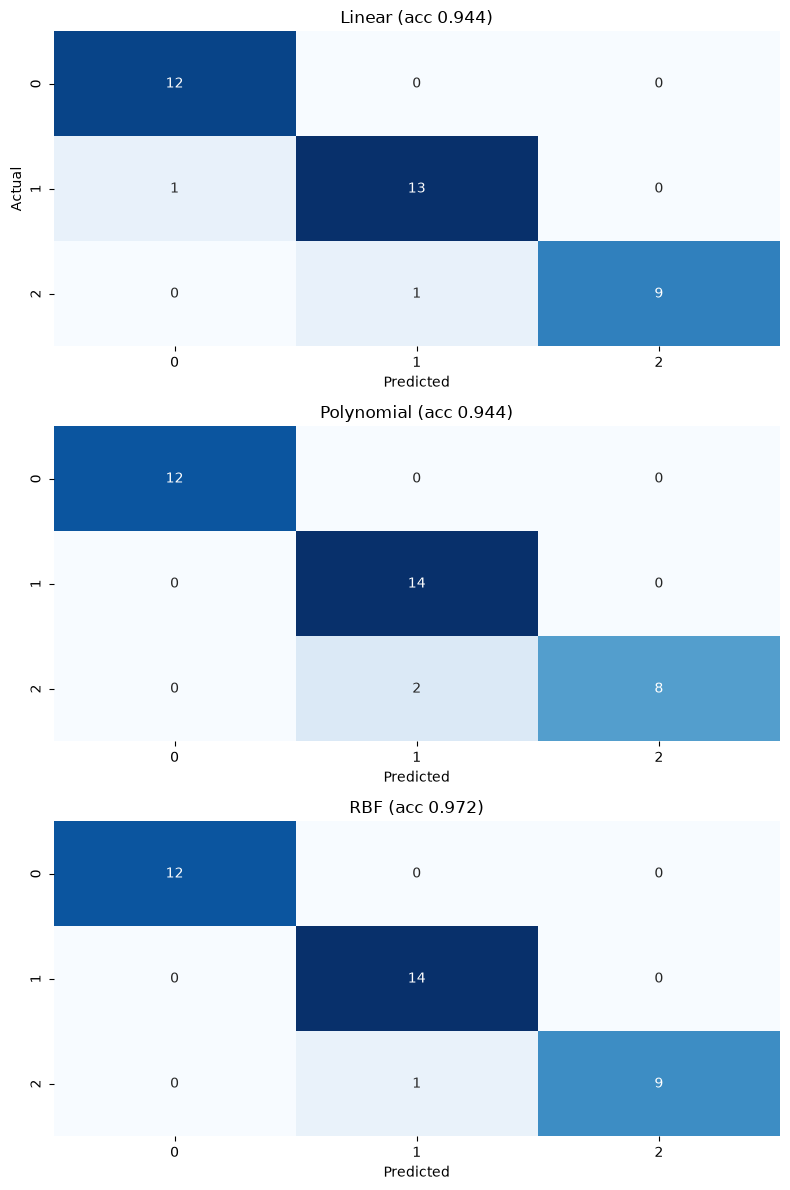

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report
)

wine = load_wine()
X, y = wine.data, wine.target
print("Shape:", X.shape, "| Class counts:", pd.Series(y).value_counts().sort_index().to_dict())
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

sc = StandardScaler()
X_train = sc.fit_transform(X_train); X_test = sc.transform(X_test)

kernels = {"Linear": SVC(kernel="linear", C=1),
           "Polynomial": SVC(kernel="poly", degree=3, coef0=1, C=1),
           "RBF": SVC(kernel="rbf", C=1, gamma="scale")}

rows, preds = [], {}
for name, m in kernels.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    preds[name] = p
    P, R, F, _ = precision_recall_fscore_support(y_test, p, average="macro")
    rows.append([name, accuracy_score(y_test, p), P, R, F, m.n_support_.sum()])

print("\n", pd.DataFrame(rows, columns=["Kernel", "Accuracy", "Precision", "Recall", "F1", "Support Vectors"])
      .round(4).to_string(index=False))

print("\nClassification report (RBF):\n", classification_report(y_test, preds["RBF"]))
print("Effect of C and gamma (RBF, 5-fold CV accuracy):")
for C, g in [(0.1, 0.01), (1, 0.1), (10, 0.1), (10, 10)]:
    acc = cross_val_score(SVC(kernel="rbf", C=C, gamma=g), X_train, y_train, cv=5).mean()
    print(" C = %-4s gamma = %-5s > %.4f" % (C, g, acc))

fig, ax = plt.subplots(3, 1, figsize=(8, 12))
for a, (name, p) in zip(ax, preds.items()):
    sns.heatmap(confusion_matrix(y_test, p), annot=True, cmap="Blues", cbar=False, ax=a)
    a.set_title("%s (acc %.3f)" % (name, accuracy_score(y_test, p)))
    a.set_xlabel("Predicted")

ax[0].set_ylabel("Actual")
plt.tight_layout()